In [138]:
from google.colab import drive
import os, math, random, shutil, time, json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import f1_score, confusion_matrix

### **Konfigurasi Koneksi Google Drive**
---
Link : https://drive.google.com/drive/folders/1JaCpeL-pBl_89Jkz77gHVmRO-TUKXUpi?usp=sharing

In [139]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [140]:
ZIP_DRIVE = '/content/drive/MyDrive/Pembelajaran Mesin/data/GCD-dataset.zip'
ZIP_LOCAL = '/content/GCD-dataset.zip'
EXTRACT_DIR = '/content/GCD-dataset'

def find_data_root(base):
    for root, dirs, _ in os.walk(base):
        dirs[:] = [d for d in dirs if not d.startswith('__MACOSX')]
        if {'train', 'val', 'test'} <= set(dirs):
            return root
    raise FileNotFoundError(f"Folder train/val/test tidak ditemukan di {base}")

if not os.path.isdir(EXTRACT_DIR):
    t0 = time.time()
    tmp_dir = EXTRACT_DIR + '_tmp'
    shutil.rmtree(tmp_dir, ignore_errors=True)
    shutil.copy(ZIP_DRIVE, ZIP_LOCAL)
    shutil.unpack_archive(ZIP_LOCAL, tmp_dir)
    os.rename(tmp_dir, EXTRACT_DIR)
    os.remove(ZIP_LOCAL)
    print(f"Ekstrak selesai dalam {time.time()-t0:.0f}s")

LOCAL_DATA = find_data_root(EXTRACT_DIR)
print("Dataset:", LOCAL_DATA, os.listdir(LOCAL_DATA))

Dataset: /content/GCD-dataset ['test', 'val', 'train']


**KONFIGURASI**

In [141]:
from sys import version
# ---- Mode & reproducibility ----
DEBUG         = False        # True = uji cepat di CPU, False = training penuh (GPU)
DEBUG_BATCHES = 3             # jumlah batch per epoch saat DEBUG
SEED          = 42

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()


# ---- Data ----
NUM_CLASSES = 7
IMG_SIZE    = 224                         # 224 x 224 piksel, RGB
MEAN        = [0.485, 0.456, 0.406]       # normalisasi ImageNet
STD         = [0.229, 0.224, 0.225]
EPS         = 1e-6
NUM_WORKERS = 2
NORM_MODE   = 'imagenet'                  # 'imagenet' = ÷255 lalu mean/std ImageNet | '01' = hanya ÷255

# ---- Data GCD asli + augmentasi on-the-fly ----
N_SPLIT = (8340, 1471, 9000)        # DATASET_SPLIT.md
IMBALANCE = 'sampler'               # 'sampler' | 'weights' | 'none'
SAMPLES_PER_EPOCH = 7 * 3000        # hanya untuk 'sampler'

# ---- Arsitektur ----
USE_SE        = True
USE_SCCONV    = True
USE_BRANCH    = False
USE_BR        = True
BRANCH_PAPER  = False   # True = cabang Block 1 persis jurnal: Pool→FC2048→Drop0.8→FC1024→Drop0.8, fusi f1+f2
ND_CH         = 8
LAM_SCALE     = 10.0


SE_REDUCTION      = 16     # rasio reduksi r (Hu et al., 2018)
SE_INIT_BIAS      = 3.0    # sigmoid(3) ≈ 0,953 -> SE awal mendekati identitas
P_DROP            = 0.8    # dropout cabang Block 1
P_DROP_TOP        = 0.5    # dropout Top Block (sebelum FC512 dan FC32)
FUSION_ALPHA_INIT = 1.0     # α awal fusi: f1 + α·f2 (1.0 = penjumlahan langsung)
TOP_POOL          = 7       # 7 = Top Block asli (7x7x1024) | 1 = GAP (opsional, run R5)
TOP_DIMS          = [TOP_POOL * TOP_POOL * 1024, 632, 512, 32]  # Flatten -> FC1024 -> FC512 -> FC32
BRANCH_DIMS       = [256, 2048, 1024]                           # GAP Block 1 -> FC2048 -> FC1024

# ---- Optimasi (AdamW + Focal Loss) ----
WEIGHT_DECAY  = 1e-2
FOCAL_GAMMA   = 2.0       # faktor fokus γ (Lin et al., 2017)
GRAD_CLIP     = 5.0       # batas norma gradien

# ---- Perbaikan generalisasi (v2) ----
GROUPED_SPLIT   = False     # split train/val ulang per grup near-duplicate (anti-bocor)
GROUP_THR       = 0.95    # cos-similarity untuk dianggap "frame yang sama"
STRONG_AUG      = False   # rotasi 180°, vflip, hue, grayscale, equalize
LABEL_SMOOTHING = 0.0     # 0.1 pada run R3
MIXUP_P         = 0.0     # 0.3 pada run R4 (peluang batch di-MixUp)
MIXUP_ALPHA     = 0.2
LECUN_UNIFORM   = 3


# ---- Jadwal training ----
PHASES = [
    (20, 1e-4, 'Top Block (bobot ImageNet beku)'),
    (30, 1e-5, 'Adaptasi Top Block'),
    (40, 5e-5, 'Unfreeze Dense Block 3-4 (Keras: conv4, lapisan 141+)'),
    (60, 1e-5, 'Partial Fine-Tuning Optimization (Dense Block 3-4, smoothing)'),
    (80, 1e-6, 'Full Defrost (seluruh backbone end-to-end)'),
]

if DEBUG:  # 1 epoch per tahap, otomatis ikut jumlah tahap
    PHASES = [(i, lr, desc) for i, (_, lr, desc) in enumerate(PHASES, 1)]

BATCH_SIZE    = 8 if DEBUG else 32
UNFREEZE_PHASE = 3                    # tahap saat Dense Block 3-4 dibuka
FULL_UNFREEZE_PHASE = 5
EPOCHS = PHASES[-1][0]

EPOCH_LIMIT = None                    # uji cepat 10 epoch | None = jadwal penuh
if EPOCH_LIMIT:
    EPOCHS = min(EPOCHS, EPOCH_LIMIT)

LR            = PHASES[0][1]          # alias untuk sel lain
LR_FT         = PHASES[2][1]
LR_FULL       = PHASES[4][1]
FREEZE_EPOCHS = PHASES[1][0]          # epoch terakhir dengan bobot ImageNet beku
PATIENCE      = 7                     # early stopping, hanya aktif di tahap 3
EARLY_STOP    = False                 # sementara dimatikan; set True untuk mengaktifkan lagi

# ---- Path & nama run ----
PROJECT_DIR = '/content/drive/MyDrive/Pembelajaran Mesin'
CKPT_DIR    = f'{PROJECT_DIR}/artefak/checkpoints'
RESULT_DIR  = f'{PROJECT_DIR}/artefak/hasil'
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

VERSION  = "_Versi01"
TAG      = "_debug" if DEBUG else ""
RUN_NAME = ("cloud")

CKPT_PATH = f'{CKPT_DIR}/{RUN_NAME}{VERSION}{TAG}.pth'
RESUME = True
LAST_PATH = CKPT_PATH.replace('.pth', '_last.pth')

# Lanjutkan dari run 4 tahap. Disalin (bukan rename), jadi hasil 4 tahap tetap utuh.
PREV_RUN = RUN_NAME.replace(f'_{len(PHASES)}phase', '_4phase')
PREV_LAST = f'{CKPT_DIR}/{PREV_RUN}{TAG}_last.pth'
PREV_BEST = f'{CKPT_DIR}/{PREV_RUN}{TAG}.pth'
if RESUME and not os.path.exists(LAST_PATH) and os.path.exists(PREV_LAST):
    shutil.copy(PREV_LAST, LAST_PATH)
    shutil.copy(PREV_BEST, CKPT_PATH)
    print("Checkpoint 4 tahap disalin -> lanjut ke tahap 5:", PREV_RUN)

print(f"DEBUG={DEBUG} | batch={BATCH_SIZE} | epoch={EPOCHS} (freeze {FREEZE_EPOCHS}) | "
      f"AdamW lr={LR:g} wd={WEIGHT_DECAY:g} | γ={FOCAL_GAMMA}")
print("Checkpoint:", CKPT_PATH)

if DEBUG:
    for f in (CKPT_PATH, LAST_PATH):
        if os.path.exists(f): os.remove(f)

DEBUG=False | batch=32 | epoch=80 (freeze 30) | AdamW lr=0.0001 wd=0.01 | γ=2.0
Checkpoint: /content/drive/MyDrive/Pembelajaran Mesin/artefak/checkpoints/cloud_Versi01.pth


# **CloudDenseNet**


---
1. Perubahan Dimensi Tensor (Input 224×24)
*   **Gambar Input Awal** : [1, 3, 224, 224]
*   **Kernel**            : 7
*   **Setelah Conv 7×7**  : [Stride 2, Padding 3]

<p>ukuran yang siap masuk ke Dense Block 1 adalah 128×128 piksel dengan 64 channel</p>

---

$$
\text{Output} = \left\lfloor \frac{\text{Input} - \text{Kernel} + 2 \times \text{Padding}}{\text{Stride}} \right\rfloor + 1
$$

## **Stuktur Utama**

---



In [142]:
class CloudDenseNet(nn.Module):
    def __init__(self, growth_rate=32, n_cls=NUM_CLASSES):
        super().__init__()



        kw = dict(growth_rate=growth_rate, nd=ND_CH, use_se=USE_SE)

        # ===== Backbone =====
        # Stem: 3 -> 64, 512 -> 128
        self.conv     = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn       = nn.BatchNorm2d(64)
        self.relu     = nn.ReLU(inplace=True)
        self.maxpool  = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Block 1: 64 -> 256 (128×128) | Trans 1: -> 128 (64×64)
        self.block1 = DenseBlock1(num_layers=6,  in_channels=64,  **kw)
        self.se1, self.sa  = SEBlock(256),  SpatialAttnBR()
        self.trans1 = TransitionLayer1(256, 128)

        # Block 2: 128 -> 512 (64×64) | Trans 2: -> 256 (32×32)
        self.block2 = DenseBlock2(num_layers=12, in_channels=128, **kw)
        self.se2, self.sa2 = SEBlock(512),  SpatialAttnBR()
        self.trans2 = TransitionLayer2(512, 256)

        # Block 3: 256 -> 1024 (32×32) | Trans 3: -> 512 (16×16)
        self.block3 = DenseBlock3(num_layers=24, in_channels=256, **kw)
        self.se3, self.sa3 = SEBlock(1024), SpatialAttnBR()
        self.trans3 = TransitionLayer3(1024, 512)

        # Block 4: 512 -> 1024 (16×16) | BN akhir
        self.block4 = DenseBlock4(num_layers=16, in_channels=512, **kw)
        self.se4, self.sa4 = SEBlock(1024), SpatialAttnBR()
        self.norm5 = nn.BatchNorm2d(1024)

        # ===== Top Block =====
        self.top = TopBlock()

    def forward(self, x, lam=None, return_all=False):
        s  = self.maxpool(self.relu(self.bn(self.conv(x))))       # (B, 64, 128, 128)
        b1 = self.sa(self.se1(self.block1(s)), lam)               # (B, 256, 128, 128)
        t1 = self.trans1(b1)
        b2 = self.sa2(self.se2(self.block2(t1)), lam)             # (B, 512, 64, 64)
        t2 = self.trans2(b2)
        b3 = self.sa3(self.se3(self.block3(t2)), lam)             # (B, 1024, 32, 32)
        t3 = self.trans3(b3)
        b4 = self.sa4(self.se4(self.block4(t3)), lam)             # (B, 1024, 16, 16)

        out = F.relu(self.norm5(b4))                               # (B, 1024, 16, 16)
        logits = self.top(out)                                     # ← (B, 7)
        if return_all:
            return {'stem': s, 'block1': b1, 'trans1': t1, 'block2': b2, 'trans2': t2,
                    'block3': b3, 'trans3': t3, 'block4': b4, 'out': out,
                    'logits': logits}                              # ← tambah logits
        return logits

In [143]:
@torch.no_grad()
def nolkan_input_nd(model, g=32, nd=ND_CH):
    """Bobot yang membaca channel ND diisi 0 → awal training = ImageNet murni."""
    for b, c0 in [(1, 64), (2, 128), (3, 256), (4, 512)]:
        blk = getattr(model, f'block{b}')
        posisi = lambda n: [c0 + j * g + (g - nd) + k for j in range(n) for k in range(nd)]
        for i, layer in enumerate(blk.layers):
            layer.h[2].weight[:, posisi(i)] = 0                     # conv1×1 layer berikutnya
        if hasattr(model, f'trans{b}'):
            getattr(model, f'trans{b}').conv.weight[:, posisi(len(blk.layers))] = 0   # transisi
    return model

In [144]:
def muat_imagenet(model):
    """Salin bobot DenseNet121 ImageNet ke backbone CloudDenseNet."""
    tv = models.densenet121(weights='IMAGENET1K_V1').features.state_dict()
    own = model.state_dict()
    nama = {'norm1': 'h.0', 'conv1': 'h.2', 'norm2': 'h.3', 'conv2': 'conv'}
    sd = {}
    for k, v in tv.items():
        k = (k.replace('conv0', 'conv').replace('norm0', 'bn')
              .replace('transition', 'trans').replace('trans1.norm', 'trans1.bn')
              .replace('trans2.norm', 'trans2.bn').replace('trans3.norm', 'trans3.bn'))
        if k.startswith('denseblock'):                       # denseblock1.denselayer1.norm1.weight
            b, l, m, w = k.split('.')
            k = f'block{b[-1]}.layers.{int(l[10:]) - 1}.{nama[m]}.{w}'
        if k in own and v.shape != own[k].shape: v = v[:own[k].shape[0]]  # ← 32 → 24 filter
        sd[k] = v
    hasil = model.load_state_dict(sd, strict=False)
    model.imagenet_keys = {k for k in sd if k in own}
    print('ImageNet dimuat:', len(sd) - len(hasil.unexpected_keys), 'tensor')
    return model

In [145]:
BLOK_FT = ('block3.', 'se3.', 'sa3.', 'trans3.', 'block4.', 'se4.', 'sa4.', 'norm5.')

def _lapor(model, judul):
    lat = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    print(f"[{judul}] dilatih {lat:,} / {tot:,} ({100*lat/tot:.2f}%)")

def bekukan_imagenet(model, latih_baru=True, verbose=True):
    """Tahap 1–2: bobot ImageNet beku; Top Block (+ lapisan baru) dilatih."""
    for n, p in model.named_parameters():
        if n.startswith('top.'):
            p.requires_grad = True
        elif n in model.imagenet_keys:
            p.requires_grad = False
        else:   # SE, SA, log_q, log_tau. pq dilewati: pembacanya (h.2) beku = 0
            p.requires_grad = latih_baru and '.pq.' not in n
    model.bn_beku = not USE_SCCONV   # SCConv mengubah distribusi → BN harus adaptasi
    model.bn_buka = ()
    if verbose: _lapor(model, 'Beku ImageNet')

def buka_blok_3_4(model, verbose=True):
    """Tahap 3–4: Dense Block 3–4 + trans3 + norm5 ikut dilatih."""
    bekukan_imagenet(model, verbose=False)
    for n, p in model.named_parameters():
        if n.startswith(BLOK_FT):
            p.requires_grad = True
    model.bn_buka = BLOK_FT
    if verbose: _lapor(model, 'Buka Block 3–4')

def buka_semua(model, verbose=True):
    """Tahap 5: full defrost."""
    for p in model.parameters():
        p.requires_grad = True
    model.bn_beku, model.bn_buka = False, ()
    if verbose: _lapor(model, 'Full defrost')

def set_bn_beku_eval(model):
    """Dipanggil setelah model.train(): BN ImageNet yang beku tidak update running stats."""
    if not getattr(model, 'bn_beku', False):
        return
    for n, m in model.named_modules():
        if (isinstance(m, nn.BatchNorm2d) and f'{n}.weight' in model.imagenet_keys
                and not n.startswith(getattr(model, 'bn_buka', ()))):
            m.eval()

## **Block CloudDense**

---



In [146]:
class DenseBlock1(nn.Module):
    """Wadah untuk menyusun 6 DenseLayer secara berurutan"""
    def __init__(self, num_layers=6, in_channels=64, growth_rate=32, nd=0, use_se=False):
      super().__init__()
      self.layers = nn.ModuleList([
          DenseLayer(in_channels + i * growth_rate, growth_rate, nd=nd, use_se=use_se)
          for i in range(num_layers)])

    def forward(self, x):
        feats = [x]
        for layer in self.layers:
            feats.append(layer(feats))
        return torch.cat(feats, 1)

In [147]:
class DenseBlock2(DenseBlock1):
    """12 dense layer: 128 -> 128 + 12·32 = 512 channel, spasial tetap 64×64."""
    def __init__(self, num_layers=12, in_channels=128, growth_rate=32, nd=0, use_se=False):
        super().__init__(num_layers, in_channels, growth_rate, nd, use_se)

In [148]:
class DenseBlock3(DenseBlock1):
    """24 dense layer: 256 -> 256 + 24·32 = 1024 channel, spasial tetap 32×32."""
    def __init__(self, num_layers=24, in_channels=256, growth_rate=32, nd=0, use_se=False):
        super().__init__(num_layers, in_channels, growth_rate, nd, use_se)


In [149]:
class DenseBlock4(DenseBlock1):
    """16 dense layer: 512 -> 512 + 16·32 = 1024 channel, spasial tetap 16×16."""
    def __init__(self, num_layers=16, in_channels=512, growth_rate=32, nd=0, use_se=False):
        super().__init__(num_layers, in_channels, growth_rate, nd, use_se)

In [150]:
class DenseLayer(nn.Module):
    """BN-ReLU-Conv1x1(4k)-BN-ReLU → SE → SCConv3x3(k). Opsional: ND (nd channel)."""
    def __init__(self, in_channels, growth_rate=32, nd=0, use_se=False, eps=1e-3):
        super().__init__()
        mid = 4 * growth_rate # 128
        self.h = nn.Sequential(
            nn.BatchNorm2d(in_channels), nn.ReLU(inplace=True),
            nn.Conv2d(in_channels, mid, 1, bias=False),
            nn.BatchNorm2d(mid), nn.ReLU(inplace=True))
        self.se = SEBlock(mid) if use_se else nn.Identity()                       # ← SE pada bottleneck (128)
        self.conv = (SCConv(mid, growth_rate - nd, 3, padding=1) if USE_SCCONV
                     else nn.Conv2d(mid, growth_rate - nd, 3, padding=1, bias=False))
        self.pq = nn.Conv2d(mid, 2 * nd, 3, padding=1, bias=False) if nd else None
        self.eps = eps

    def forward(self, x):
        x = torch.cat(x, 1) if isinstance(x, (list, tuple)) else x
        h = self.se(self.h(x))                                                    # ← H_l dulu, lalu SE
        out = self.conv(h)                                                        # ← SCConv
        if self.pq is not None:
            P, Q = F.softplus(self.pq(h)).chunk(2, 1)
            out = torch.cat([out, (P - Q) / (P + Q + self.eps)], 1)
        return out

In [151]:
class TransitionLayer1(nn.Module):
    """Mengecilkan channel sebesar 50% dan mereduksi ukuran spasial hingga setengahnya"""
    def __init__(self, in_channels=256, out_channels=128):
        super(TransitionLayer1, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.pool(self.conv(self.relu(self.bn(x))))

In [152]:
class TransitionLayer2(nn.Module):
    """BN-ReLU-Conv1x1 (512 -> 256) -> AvgPool 2×2 (64×64 -> 32×32)."""
    def __init__(self, in_channels=512, out_channels=256):
        super().__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, out_channels, 1, bias=False)
        self.pool = nn.AvgPool2d(2, 2)

    def forward(self, x):
        return self.pool(self.conv(self.relu(self.bn(x))))

In [153]:
class TransitionLayer3(TransitionLayer2):
    """BN-ReLU-Conv1x1 (1024 -> 512) -> AvgPool 2×2 (32×32 -> 16×16)."""
    def __init__(self, in_channels=1024, out_channels=512):
        super().__init__(in_channels, out_channels)


**SEBlock**


---



In [154]:
class SEBlock(nn.Module):
    def __init__(self, in_channels, reduction_ratio=SE_REDUCTION, init_bias=SE_INIT_BIAS):
        super().__init__()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        mid = max(1, in_channels // reduction_ratio)
        self.excitation = nn.Sequential(
            nn.Conv2d(in_channels, mid, 1, bias=True), nn.ReLU(inplace=True),
            nn.Conv2d(mid, in_channels, 1, bias=True), nn.Sigmoid())
        nn.init.zeros_(self.excitation[2].weight)                 # awal ≈ identitas
        nn.init.constant_(self.excitation[2].bias, init_bias)     # sigmoid(3) ≈ 0,953

    def forward(self, x):
        return x * self.excitation(self.global_pool(x))

**SCConv**

---



In [155]:
class SCConv(nn.Module):
  def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, padding=1,
                 q_init=1e-2, tau_init=1.0, eps=1e-6):
    super().__init__()
    self.stride, self.padding, self.eps = stride, padding, eps
    self.weight = nn.Parameter(torch.empty(out_ch, in_ch, kernel_size, kernel_size))
    nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
    self.register_buffer('ones', torch.ones(1, in_ch, kernel_size, kernel_size))
    self.log_q   = nn.Parameter(torch.tensor(math.log(q_init)))                 # q > 0
    self.log_tau = nn.Parameter(torch.full((out_ch,), math.log(tau_init)))      # τ > 0 per channel

  def forward(self, x):
    with torch.autocast(device_type=x.device.type, enabled=False):   # paksa fp32
        x = F.pad(x.float(), (self.padding,) * 4, mode='reflect')
        w = self.weight.float()
        k = w.shape[-1]
        dot = F.conv2d(x, w, stride=self.stride)
        # ||x|| per patch = jumlah x² lintas channel, lalu jumlah jendela k×k.
        # Penjumlahan langsung -> tidak bisa negatif (beda dengan conv cuDNN).
        sq = x.pow(2).sum(1, keepdim=True)
        x_norm = (F.avg_pool2d(sq, k, stride=self.stride, divisor_override=1)
                  .clamp_min(0) + self.eps).sqrt()
        w_norm = w.flatten(1).norm(dim=1).view(1, -1, 1, 1)
        q = self.log_q.exp()
        tau = self.log_tau.exp().view(1, -1, 1, 1)
        cos = (dot / ((x_norm + q) * (w_norm + self.eps))).clamp(-1.0, 1.0)
        return torch.sign(dot) * (cos.abs() + self.eps).pow(tau)


**TopBlock**

---



In [156]:
class TopBlock(nn.Module):
    def __init__(self, in_channels=1024, n_cls=NUM_CLASSES, p=P_DROP_TOP):
        super().__init__()
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()

        mid_features = 32

        self.bottleneck = nn.Sequential(
            nn.Linear(in_channels, mid_features),
            nn.BatchNorm1d(mid_features),
            nn.ReLU(inplace=True),
            nn.Dropout(p)
        )

        # 3. Final Classification Layer
        self.fc = nn.Linear(mid_features, n_cls)

    def forward(self, x):
        x = self.global_pool(x)  # Shape: [B, 1024, 1, 1]
        x = self.flatten(x)      # Shape: [B, 1024]
        x = self.bottleneck(x)   # Shape: [B, 32]
        return self.fc(x)        # Shape: [B, 7] (Logits untuk CrossEntropyLoss)

**Inisialisasi bobot baru: LeCun Uniform**


---

In [157]:
def lecun_uniform_(tensor):
    fan_in = tensor[0].numel()
    limit = math.sqrt(3.0 / fan_in)
    with torch.no_grad():
        return tensor.uniform_(-limit, limit)

def init_new_layers(m):
    """Hanya untuk lapisan BARU (SE, cabang B1, Top Block). Jangan .apply ke seluruh model."""
    if isinstance(m, (nn.Linear, nn.Conv2d)):
        lecun_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.ones_(m.weight)
        nn.init.zeros_(m.bias)


**FocalLoss**


---



In [158]:
class FocalLoss(nn.Module):
  def __init__(self, alpha=1.0, gamma=2.0, reduction="mean"):
    super(FocalLoss, self).__init__()
    self.alpha      = alpha
    self.gamma      = gamma
    self.reduction  = reduction
    self.ce_loss    = nn.CrossEntropyLoss(reduction='none')

  def forward(self, logits, target):
    ce_loss = self.ce_loss(logits, target)
    pt = torch.exp(-ce_loss)
    focal_loss = self.alpha * (1-pt)**self.gamma * ce_loss

    if self.reduction == 'mean':
      return focal_loss.mean()
    elif self.reduction == 'sum':
      return focal_loss.sum()
    else :
      return focal_loss

**Modifikasi**

---



In [159]:
class SpatialAttn(nn.Module):
    def __init__(self, k=7, init_bias=3.0, keep_map=False):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, padding_mode='reflect')
        nn.init.zeros_(self.conv.weight); nn.init.constant_(self.conv.bias, init_bias)
        self.keep_map = keep_map          # True hanya saat visualisasi
        self.map = None

    def forward(self, x):
        m = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        a = torch.sigmoid(self.conv(m))
        if self.keep_map:
            self.map = a.detach()         # tanpa graf autograd
        return x * a

In [160]:
class EdgeLayer(nn.Module):
    def __init__(self):
        super().__init__()
        sx = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]])
        lap = torch.tensor([[0., 1, 0], [1, -4, 1], [0, 1, 0]])
        self.register_buffer('k', torch.stack([sx, sx.T, lap]).unsqueeze(1))   # (3,1,3,3)
    def forward(self, x):
        g = x.mean(1, keepdim=True)                                           # grayscale
        return torch.cat([x, F.conv2d(F.pad(g, (1,) * 4, mode='reflect'), self.k)], 1)

In [161]:
def lambda_relatif(x01, eps=EPS):
    """λ dikurangi median per gambar → >0 lebih biru dari biasanya, <0 lebih putih (awan)."""
    lam = br_ratio_lambda(x01, eps)                     # [...,H,W]
    valid = valid_mask(x01)
    med = torch.stack([l[v].median() if v.any() else l.new_tensor(0.)
                       for l, v in zip(lam.reshape(-1, *lam.shape[-2:]),
                                       valid.reshape(-1, *valid.shape[-2:]))])
    med = med.reshape(*lam.shape[:-2], 1, 1)
    # return ((lam - med) * valid).clamp(-0.3, 0.3)
    return 0.5 * torch.tanh((lam - med) / 0.5) * valid      # ← soft clamp, |λ| < 0.5

In [162]:
class SpatialAttnBR(SpatialAttn):
    def __init__(self, k=7, init_bias=3.0, keep_map=False):
        super().__init__(k, init_bias, keep_map)
        self.conv = nn.Conv2d(3, 1, k, padding=k // 2, padding_mode='reflect')  # +1 channel λ
        nn.init.zeros_(self.conv.weight); nn.init.constant_(self.conv.bias, init_bias)

    def forward(self, x, lam=None):
        if lam is None:                                    # tanpa λ → perilaku = SpatialAttn biasa
            lam = x.new_zeros(x.shape[0], 1, *x.shape[-2:])
        else:
            lam = F.interpolate(lam, size=x.shape[-2:], mode='area').to(x.dtype) * LAM_SCALE
        m = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True), lam], 1)
        a = torch.sigmoid(self.conv(m))
        if self.keep_map:
            self.map = a.detach()
        return x * a

In [163]:
# ===== Tahap 1: rasio B/R =====
def br_ratio_lambda(x, eps=EPS):
    """x: [...,3,H,W] RGB [0,1] (BELUM dinormalisasi) → λ [...,H,W]."""
    r, b = x[..., 0, :, :], x[..., 2, :, :]
    return (b - r) / (b + r + eps)

def valid_mask(x, dark=0.10, sat=0.97):
    """True = piksel layak dinilai (bukan gelap, bukan silau)."""
    return (x.amax(-3) > dark) & (x.amin(-3) < sat)

TF_01 = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                            transforms.ToTensor()])          # TANPA Normalize

# **Ujicoba**

---



In [164]:
model = CloudDenseNet(growth_rate=32, n_cls=NUM_CLASSES)
model.eval()

CloudDenseNet(
  (conv): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (block1): DenseBlock1(
    (layers): ModuleList(
      (0): DenseLayer(
        (h): Sequential(
          (0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (1): ReLU(inplace=True)
          (2): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (4): ReLU(inplace=True)
        )
        (se): SEBlock(
          (global_pool): AdaptiveAvgPool2d(output_size=1)
          (excitation): Sequential(
            (0): Conv2d(128, 8, kernel_size=(1, 1), stride=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(8, 

In [165]:
x = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    res = model(x, return_all=True)

In [166]:
# ==========================================
# 3. HELPER PADDING ARRAY & MATRIKS NUMPY
# ==========================================
def to_numpy_shape(tensor_shape):
    """Mengubah bentuk tensor menjadi array numpy sepanjang 4 elemen (di-pad dengan 0 jika 2D)"""
    s_list = list(tensor_shape)
    while len(s_list) < 4:
        s_list.append(0)  # Menambahkan padding 0 untuk dimensi H dan W pada Logits
    return np.array(s_list)

In [167]:
# ==========================================
# 3. DATA COLLECTION WITH STRUCTURED ARRAY
# ==========================================
hitung = lambda *mods: sum(p.numel() for m in mods for p in m.parameters())

raw_data = [
    ("Input Gambar",       np.array([-1, -1, -1, -1]),          to_numpy_shape(x.shape),             0),
    ("Stem Block",         to_numpy_shape(x.shape),             to_numpy_shape(res['stem'].shape),   hitung(model.conv, model.bn)),
    ("Dense Block 1",      to_numpy_shape(res['stem'].shape),   to_numpy_shape(res['block1'].shape), hitung(model.block1, model.se1, model.sa)),
    ("Transition 1",       to_numpy_shape(res['block1'].shape), to_numpy_shape(res['trans1'].shape), hitung(model.trans1)),
    ("Dense Block 2",      to_numpy_shape(res['trans1'].shape), to_numpy_shape(res['block2'].shape), hitung(model.block2, model.se2, model.sa2)),
    ("Transition 2",       to_numpy_shape(res['block2'].shape), to_numpy_shape(res['trans2'].shape), hitung(model.trans2)),
    ("Dense Block 3",      to_numpy_shape(res['trans2'].shape), to_numpy_shape(res['block3'].shape), hitung(model.block3, model.se3, model.sa3)),
    ("Transition 3",       to_numpy_shape(res['block3'].shape), to_numpy_shape(res['trans3'].shape), hitung(model.trans3)),
    ("Dense Block 4",      to_numpy_shape(res['trans3'].shape), to_numpy_shape(res['block4'].shape), hitung(model.block4, model.se4, model.sa4)),
    ("Final Layer (Out)",  to_numpy_shape(res['block4'].shape), to_numpy_shape(res['out'].shape),    hitung(model.norm5)),
    ("Top Block (Logits)", to_numpy_shape(res['out'].shape),    to_numpy_shape(res['logits'].shape), hitung(model.top)),
]

# Structured data type definition remains 4i4 (4 integers)
dt = np.dtype([('layer_name', 'U20'), ('input_shape', '4i4'),
               ('output_shape', '4i4'), ('params', 'i8')])
numpy_table = np.array(raw_data, dtype=dt)

In [168]:
# ==========================================
# 4. PRINT PRETTY TABLE DARI NUMPY ARRAY
# ==========================================
def format_shape(shape_arr):
    if np.all(shape_arr == -1):
        return "-"
    pure_list = [int(num) for num in shape_arr]
    if pure_list[2] == 0 and pure_list[3] == 0:   # tensor 2D (logits)
        return str(pure_list[:2])
    return str(pure_list)

header = f"{'Nama Blok / Layer':<22} | {'Input Shape (Masuk)':<22} | {'Output Shape (Keluar)':<22} | {'Parameter':>12}"
print(header)
print("-" * len(header))

for row in numpy_table:
    in_str  = format_shape(row['input_shape'])
    out_str = format_shape(row['output_shape'])
    p = int(row['params'])
    p_str = "-" if p == 0 else f"{p:,}"
    print(f"{row['layer_name']:<22} | {in_str:<22} | {out_str:<22} | {p_str:>12}")

total = int(numpy_table['params'].sum())
print("-" * len(header))
print(f"{'TOTAL':<22} | {'':<22} | {'':<22} | {total:>12,}")
assert total == sum(p.numel() for p in model.parameters()), "Total tidak cocok dengan model!"

Nama Blok / Layer      | Input Shape (Masuk)    | Output Shape (Keluar)  |    Parameter
---------------------------------------------------------------------------------------
Input Gambar           | -                      | [32, 3, 224, 224]      |            -
Stem Block             | [32, 3, 224, 224]      | [32, 64, 56, 56]       |        9,536
Dense Block 1          | [32, 64, 56, 56]       | [32, 256, 56, 56]      |      412,202
Transition 1           | [32, 256, 56, 56]      | [32, 128, 28, 28]      |       33,280
Dense Block 2          | [32, 128, 28, 28]      | [32, 512, 28, 28]      |    1,090,240
Transition 2           | [32, 512, 28, 28]      | [32, 256, 14, 14]      |      132,096
Dense Block 3          | [32, 256, 14, 14]      | [32, 1024, 14, 14]     |    3,244,268
Transition 3           | [32, 1024, 14, 14]     | [32, 512, 7, 7]        |      526,336
Dense Block 4          | [32, 512, 7, 7]        | [32, 1024, 7, 7]       |    2,473,188
Final Layer (Out)      | [32, 10

In [169]:
@torch.no_grad()
def ambil_fitur(net, x):
    net.eval()
    o = net(x, return_all=True)
    return o['block1'][0].float().cpu(), o['block2'][0].float().cpu()

### **Visualisasi Output Feature Maps dari Dense Block**
Berikut adalah kode untuk memuat satu gambar sampel secara acak dari folder dataset, memprosesnya melalui model, dan menampilkan visualisasi gambar asli beserta beberapa representasi fitur (*feature maps*) setelah keluar dari `DenseBlock`.

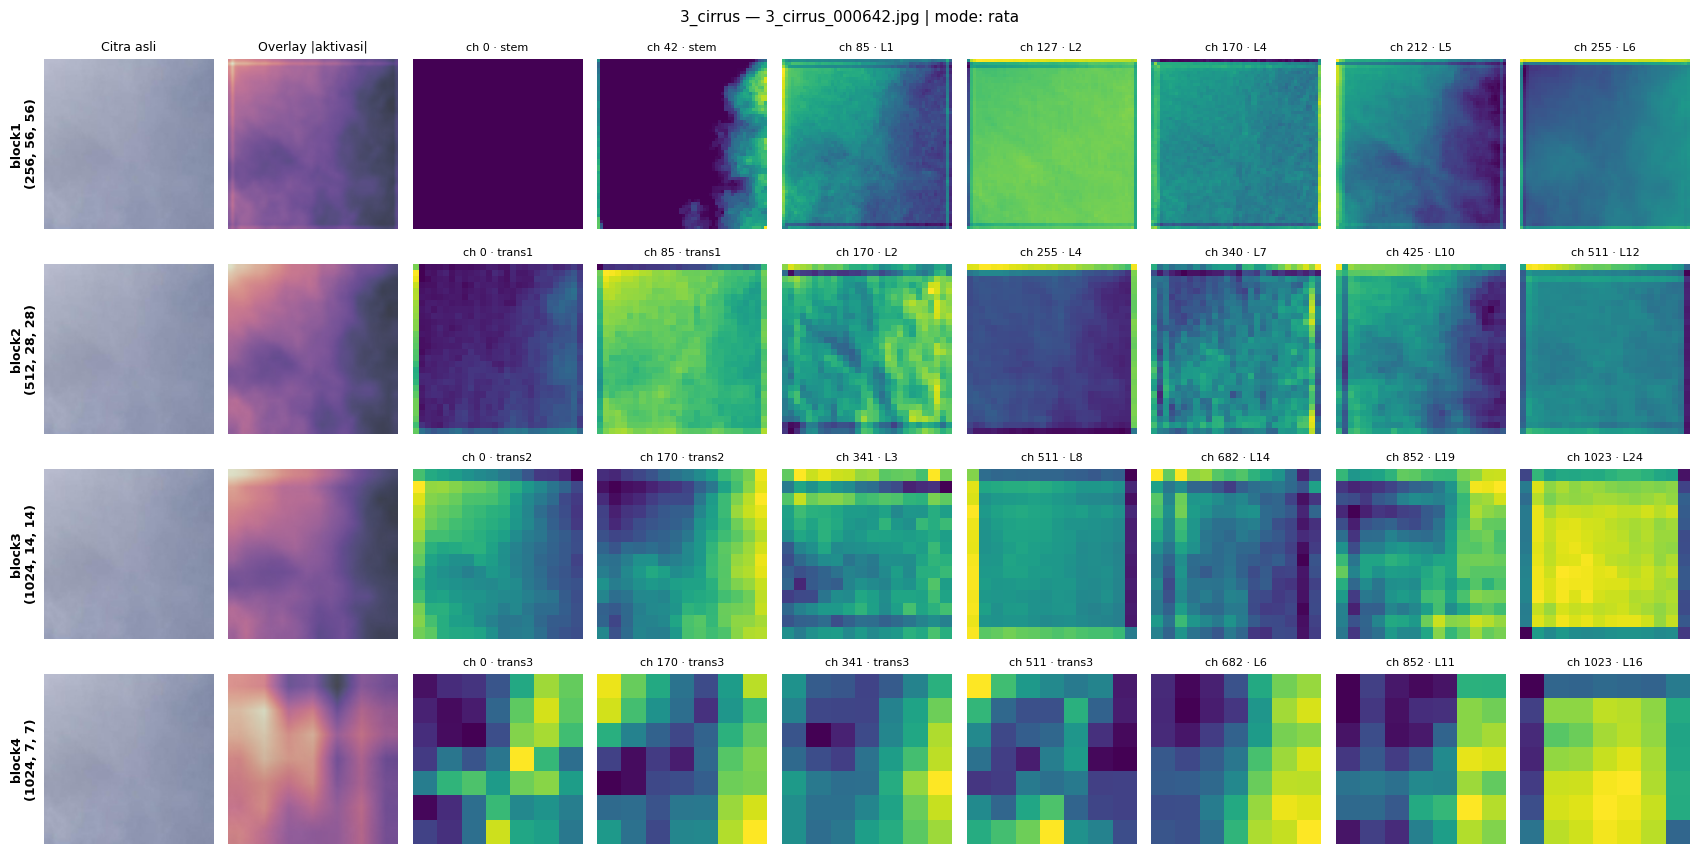

,blok,shape,kontras (mean std),channel datar (std<1e-3)
0,block1,"(256, 56, 56)",0.0166,12
1,block2,"(512, 28, 28)",0.0057,36
2,block3,"(1024, 14, 14)",0.0024,206
3,block4,"(1024, 7, 7)",0.0014,505


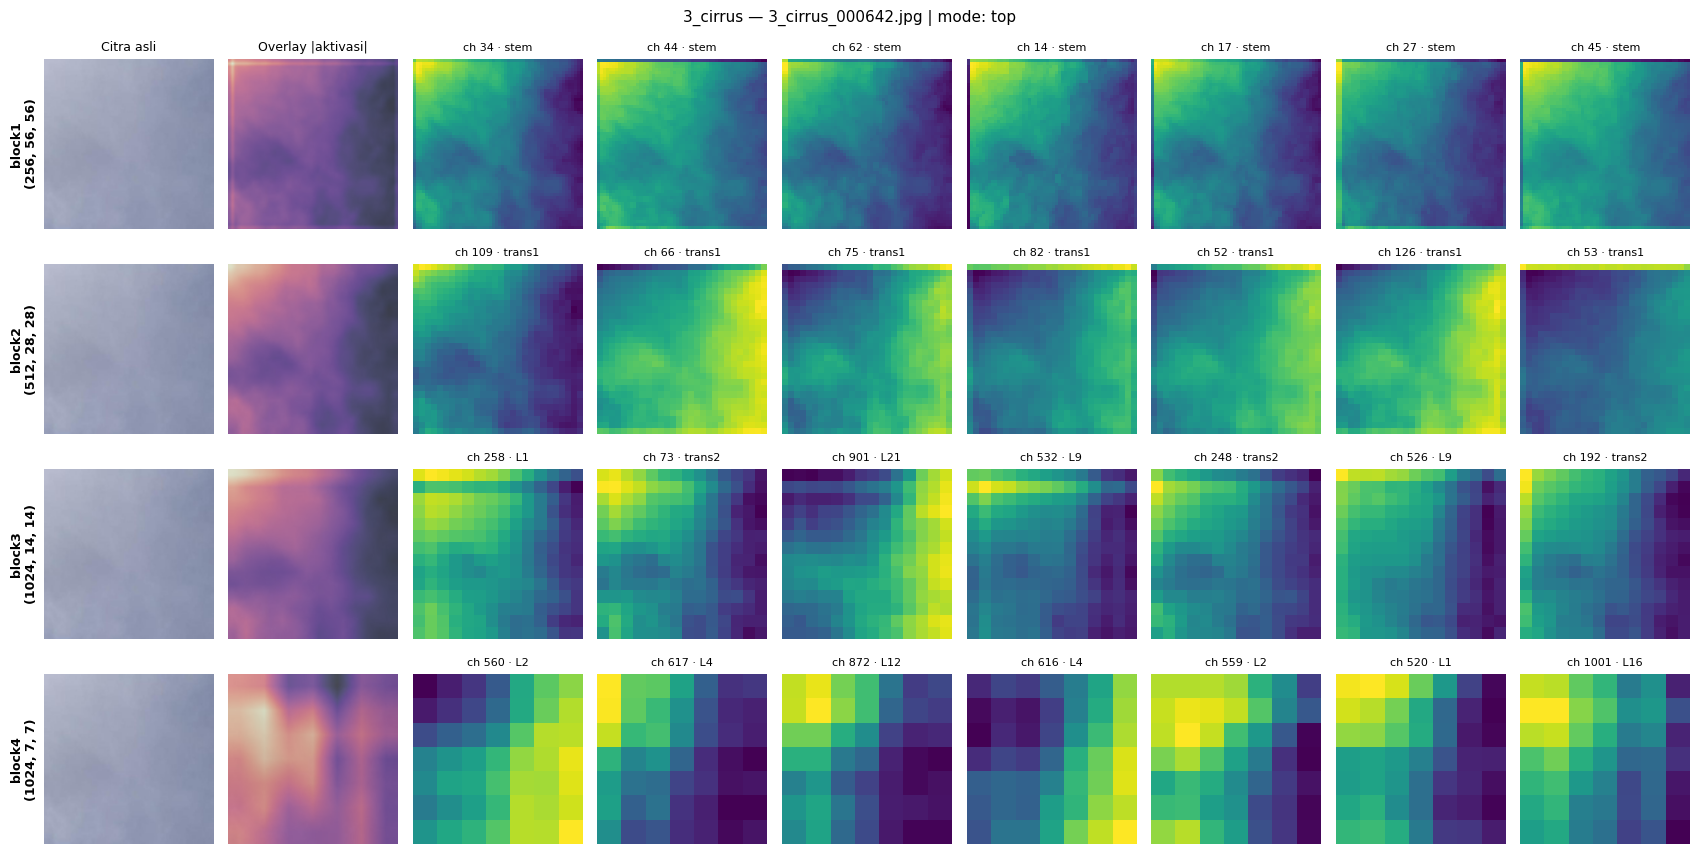

,blok,shape,kontras (mean std),channel datar (std<1e-3)
0,block1,"(256, 56, 56)",0.0166,12
1,block2,"(512, 28, 28)",0.0057,36
2,block3,"(1024, 14, 14)",0.0024,206
3,block4,"(1024, 7, 7)",0.0014,505


In [170]:
# ===== Visualisasi Feature Maps CloudDenseNet =====
GROWTH = 32
BLOK = [  # (key di return_all, channel masuk blok, asal channel awal)
    ('block1', 64,  'stem'),
    ('block2', 128, 'trans1'),
    ('block3', 256, 'trans2'),
    ('block4', 512, 'trans3'),
]

# Transform SAMA dengan training (ikut NORM_MODE)
TF_VIS = transforms.Compose(
    [transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()]
    + ([transforms.Normalize(MEAN, STD)] if NORM_MODE == 'imagenet' else []))

def asal_channel(c, c0, src):
    """Channel < c0 berasal dari input blok, sisanya sumbangan layer L1, L2, ..."""
    return src if c < c0 else f'L{(c - c0) // GROWTH + 1}'

def pilih_channel(fm, n, mode):
    if mode == 'top':                                   # n channel paling bervariasi
        return fm.flatten(1).std(1).topk(n).indices.tolist()
    return np.linspace(0, fm.shape[0] - 1, n).astype(int).tolist()  # tersebar merata

@torch.no_grad()
def ekstrak_fitur(net, path):
    net.eval()
    img = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    x = TF_VIS(img).unsqueeze(0).to(next(net.parameters()).device)
    out = net(x, return_all=True)
    return img, {k: v[0].float().cpu() for k, v in out.items()}

def tampilkan_feature_maps(net, path, n=7, mode='rata', blok=None, simpan=None):
    img, f = ekstrak_fitur(net, path)
    rows = [b for b in BLOK if blok is None or b[0] in blok]
    fig, ax = plt.subplots(len(rows), n + 2, squeeze=False,
                           figsize=(1.9 * (n + 2), 2.2 * len(rows)))

    for r, (k, c0, src) in enumerate(rows):
        fm = f[k]
        heat = F.interpolate(fm.abs().mean(0)[None, None], size=(IMG_SIZE, IMG_SIZE),
                             mode='bilinear', align_corners=False)[0, 0]
        # Kolom 0: citra asli | Kolom 1: overlay rata-rata aktivasi
        ax[r, 0].imshow(img)
        ax[r, 0].set_ylabel(f'{k}\n{tuple(fm.shape)}', fontsize=9, weight='bold')
        ax[r, 1].imshow(img); ax[r, 1].imshow(heat, cmap='magma', alpha=0.55)
        if r == 0:
            ax[r, 0].set_title('Citra asli', fontsize=9)
            ax[r, 1].set_title('Overlay |aktivasi|', fontsize=9)
        # Kolom 2..: channel terpilih
        for j, c in enumerate(pilih_channel(fm, n, mode)):
            ax[r, j + 2].imshow(fm[c], cmap='viridis')
            ax[r, j + 2].set_title(f'ch {c} · {asal_channel(c, c0, src)}', fontsize=8)

    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)

    kelas = os.path.basename(os.path.dirname(path))
    fig.suptitle(f'{kelas} — {os.path.basename(path)} | mode: {mode}', fontsize=11)
    plt.tight_layout()
    if simpan:
        fig.savefig(simpan, dpi=150, bbox_inches='tight')
    plt.show()

    # Ringkasan statistik per blok
    ringkas = []
    for k, *_ in rows:
        s = f[k].flatten(1).std(1)
        ringkas.append({'blok': k, 'shape': tuple(f[k].shape),
                        'kontras (mean std)': round(s.mean().item(), 4),
                        'channel datar (std<1e-3)': int((s < 1e-3).sum())})
    display(pd.DataFrame(ringkas))


# ===== Pakai =====
train_dir = os.path.join(LOCAL_DATA, 'train')
all_imgs = sorted(os.path.join(r, f) for r, _, fs in os.walk(train_dir)
                  for f in fs if f.lower().endswith(('.png', '.jpg', '.jpeg')))
sample_path = random.Random(SEED).choice(all_imgs)   # sama tiap run

# PENTING: pakai model yang SUDAH dilatih / sudah memuat bobot, bukan CloudDenseNet() acak
tampilkan_feature_maps(model, sample_path, mode='rata')   # channel tersebar merata
tampilkan_feature_maps(model, sample_path, mode='top')    # channel paling informatif

# **Latihan Model**
---



In [171]:
model = muat_imagenet(CloudDenseNet())

ImageNet dimuat: 725 tensor


In [172]:
weights   = models.DenseNet121_Weights.IMAGENET1K_V1
ref       = models.densenet121(weights=weights)
print("Classifier asli:", ref.classifier)    # Linear(1024 -> 1000)

Classifier asli: Linear(in_features=1024, out_features=1000, bias=True)


## **Dataset dan DataLoader**

---



In [173]:
VALID_EXT = ('.jpg', '.jpeg', '.png', '.ppm', '.bmp', '.pgm', '.tif', '.tiff', '.webp')

for split in ['train', 'val', 'test']:
    split_dir = f'{LOCAL_DATA}/{split}'
    print(f"\n=== {split} ===")
    for cls in sorted(os.listdir(split_dir)):
        cls_dir = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        files   = os.listdir(cls_dir)
        valid   = [f for f in files if f.lower().endswith(VALID_EXT)]
        subdirs = [f for f in files if os.path.isdir(os.path.join(cls_dir, f))]
        exts    = Counter(os.path.splitext(f)[1].lower() for f in files if f not in subdirs)
        flag = "  <-- MASALAH" if len(valid) == 0 else ""
        print(f"{cls:25s} gambar valid: {len(valid):5d} | ekstensi: {dict(exts)} | {flag}")


=== train ===
1_cumulus                 gambar valid:   659 | ekstensi: {'.jpg': 659} | 
2_altocumulus             gambar valid:   617 | ekstensi: {'.jpg': 617} | 
3_cirrus                  gambar valid:   980 | ekstensi: {'.jpg': 980} | 
4_clearsky                gambar valid:  1669 | ekstensi: {'.jpg': 1669} | 
5_stratocumulus           gambar valid:  1568 | ekstensi: {'.jpg': 1568} | 
6_cumulonimbus            gambar valid:  2553 | ekstensi: {'.jpg': 2553} | 
7_mixed                   gambar valid:   294 | ekstensi: {'.jpg': 294} | 

=== val ===
1_cumulus                 gambar valid:   116 | ekstensi: {'.jpg': 116} | 
2_altocumulus             gambar valid:   108 | ekstensi: {'.jpg': 108} | 
3_cirrus                  gambar valid:   173 | ekstensi: {'.jpg': 173} | 
4_clearsky                gambar valid:   294 | ekstensi: {'.jpg': 294} | 
5_stratocumulus           gambar valid:   278 | ekstensi: {'.jpg': 278} | 
6_cumulonimbus            gambar valid:   450 | ekstensi: {'.jpg': 45

## **Train Model**

---



In [174]:
# DEBUG -> paksa CPU supaya tidak memakai compute unit GPU
device = torch.device("cuda" if torch.cuda.is_available() and not DEBUG else "cpu")
print(f"Device: {device} | DEBUG: {DEBUG} | SEED: {SEED}")

Device: cuda | DEBUG: False | SEED: 42


In [175]:
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

**Augmentasi on-the-fly**

---










In [176]:
to_tensor   = transforms.Normalize(MEAN, STD)
train_tf    = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Pad(IMG_SIZE // 4, padding_mode='reflect'),
    transforms.RandomAffine(degrees=15, translate=(0.10, 0.10)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(0.5),
    *([transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
       transforms.RandomVerticalFlip(0.5)] if STRONG_AUG else []),
    transforms.ColorJitter(brightness=(0.8, 1.3), contrast=(0.8, 1.4), saturation=(0.9, 1.1),
                           hue=0.08 if STRONG_AUG else 0),
    *([transforms.RandomGrayscale(0.2), transforms.RandomEqualize(0.2)] if STRONG_AUG else []),
    transforms.ToTensor(),
])
val_tf     = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()])

In [177]:
MEAN_T = torch.tensor(MEAN).view(1, 3, 1, 1)
STD_T  = torch.tensor(STD).view(1, 3, 1, 1)

@torch.no_grad()
def siapkan_batch(x01, device):
    """x01 [B,3,H,W] di [0,1] → (x ternormalisasi, λ [B,1,H,W] atau None)."""
    x01 = x01.to(device, non_blocking=True).float()
    lam = lambda_relatif(x01).unsqueeze(1) if USE_BR else None
    x = (x01 - MEAN_T.to(device)) / STD_T.to(device) if NORM_MODE == 'imagenet' else x01
    return x, lam

In [178]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator().manual_seed(SEED)
pin = (device.type == 'cuda')

In [179]:
from torch.utils.data import WeightedRandomSampler

# 1. Dataset Initialization
train_dataset = ImageFolder(root=os.path.join(LOCAL_DATA, 'train'), transform=train_tf)
val_dataset = ImageFolder(root=os.path.join(LOCAL_DATA, 'val'), transform=val_tf)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator().manual_seed(SEED)
pin = (device.type == 'cuda')

if IMBALANCE == 'sampler':
    cnt = np.bincount(train_dataset.targets, minlength=NUM_CLASSES)
    w = torch.as_tensor(1.0 / cnt[train_dataset.targets], dtype=torch.double)
    kw = dict(sampler=WeightedRandomSampler(w, SAMPLES_PER_EPOCH, replacement=True, generator=g))
else:
    kw = dict(shuffle=True, generator=g)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, drop_last=True,
                          worker_init_fn=seed_worker, num_workers=NUM_WORKERS,
                          pin_memory=pin, persistent_workers=NUM_WORKERS > 0, **kw)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin,
    persistent_workers=NUM_WORKERS > 0,
)

# 3. Model & Optimization
model = CloudDenseNet().to(device)
model = muat_imagenet(model)
model = nolkan_input_nd(model)

criterion = FocalLoss() if FOCAL_GAMMA > 0.0 else nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

ImageNet dimuat: 725 tensor


**Loop Train**

---



In [180]:
def mixup_batch(x01, y):
    w = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))          # bobot MixUp (bukan λ B/R)
    perm = torch.randperm(x01.size(0), device=x01.device)
    return w * x01 + (1 - w) * x01[perm], y[perm], w

# ===== Jadwal tahap (menggantikan phase_of / apply_phase yang tidak ada) =====
def phase_of(epoch):
    return next((i for i, (m, _, _) in enumerate(PHASES, 1) if epoch <= m), len(PHASES))

def apply_phase(phase):
    if phase < UNFREEZE_PHASE:        bekukan_imagenet(model)
    elif phase < FULL_UNFREEZE_PHASE: buka_blok_3_4(model)
    else:                             buka_semua(model)
    for g in optimizer.param_groups:                               # LR per tahap
        g['lr'] = PHASES[phase - 1][1]

# ===== Pengaman NaN =====
def _bn_buffers(model):
    return [b for n, b in model.named_buffers() if n.endswith(('running_mean', 'running_var'))]

def lacak_nonfinite(model, x, lam):
    """Ulang batch yang gagal dengan hook -> modul pertama yang menghasilkan NaN/inf."""
    temuan, hs = [], []
    def hook(m, i, o):
        if not temuan and torch.is_tensor(o) and not torch.isfinite(o).all():
            temuan.append(f"{m._nama} ({type(m).__name__}, {o.dtype})")
    for n, m in model.named_modules():
        m._nama = n
        hs.append(m.register_forward_hook(hook))
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16,
                                         enabled=(device.type == 'cuda')):
        model(x, lam)
    for h in hs: h.remove()
    return temuan[0] if temuan else "forward bersih (NaN di loss)"

def train_one_epoch(model, loader):
    model.train()
    set_bn_beku_eval(model)
    bn = _bn_buffers(model)
    total_loss, correct, n, n_skip = 0.0, 0, 0, 0
    for i, (x01, y) in enumerate(tqdm(loader, desc='Train', leave=False)):
        if DEBUG and i >= DEBUG_BATCHES: break
        x01, y = x01.to(device, non_blocking=True), y.to(device, non_blocking=True)
        y_b, w = y, 1.0
        if MIXUP_P > 0 and random.random() < MIXUP_P:
            x01, y_b, w = mixup_batch(x01, y)                      # MixUp pada gambar mentah
        x, lam = siapkan_batch(x01, device)                        # normalisasi + peta λ B/R
        backup = [b.clone() for b in bn]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
            out = model(x, lam)
            loss = w * criterion(out, y) + (1 - w) * criterion(out, y_b)
        if not torch.isfinite(loss):
            sumber = lacak_nonfinite(model, x, lam)
            for b, s in zip(bn, backup): b.copy_(s)                # buang statistik BN tercemar
            n_skip += 1
            tqdm.write(f"⚠️ batch {i}: loss NaN dilewati | sumber: {sumber}")
            if n_skip > 20:
                raise RuntimeError("Terlalu banyak batch NaN — periksa modul sumbernya")
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / max(n, 1), correct / max(n, 1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, n, n_nan, yt, yp = 0.0, 0, 0, [], []
    for i, (x01, y) in enumerate(loader):
        if DEBUG and i >= DEBUG_BATCHES: break
        x, lam = siapkan_batch(x01, device)
        y = y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
            out = model(x, lam).float()
        n_nan += int(not torch.isfinite(out).all())
        total_loss += criterion(out, y).item() * x.size(0)
        yt.append(y.cpu()); yp.append(out.argmax(1).cpu()); n += x.size(0)
    if n_nan:
        print(f"⚠️ {n_nan} batch validasi NaN — statistik BN kemungkinan tercemar")
    yt, yp = torch.cat(yt).numpy(), torch.cat(yp).numpy()
    return total_loss / n, (yt == yp).mean(), f1_score(yt, yp, average='macro')

**Loop Traning**

In [ ]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1, bad_epochs = -1.0, 0
current_phase = 0

start_epoch = 1
if RESUME and os.path.exists(LAST_PATH):
    ck = torch.load(LAST_PATH, map_location=device, weights_only=False)
    ambil = lambda *ks: next((ck[k] for k in ks if ck.get(k) is not None), None)  # format lama & baru
    model.load_state_dict(ambil('model', 'model_state_dict'))
    optimizer.load_state_dict(ambil('optimizer', 'optimizer_state_dict'))
    if device.type == 'cuda' and ambil('scaler', 'scaler_state_dict'):
        scaler.load_state_dict(ambil('scaler', 'scaler_state_dict'))
    history = ck['history']
    best_f1 = ck.get('best_f1', max(history['val_f1'], default=-1.0))
    start_epoch = ck['epoch'] + 1
    print(f"Resume dari epoch {start_epoch} | best_f1 {best_f1:.4f}")

pbar = tqdm(range(start_epoch, EPOCHS + 1), desc="Training Progress")
for epoch in pbar:
    phase = phase_of(epoch)
    if phase != current_phase:
        apply_phase(phase)
        current_phase, bad_epochs = phase, 0
        n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
        pbar.write(f"Epoch {epoch:02d}: tahap {phase} – {PHASES[phase-1][2]} | "
                   f"lr {PHASES[phase-1][1]:g} | trainable {n_tr:,}")

    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    va_loss, va_acc, va_f1 = evaluate(model, val_loader)

    if not (math.isfinite(tr_loss) and math.isfinite(va_loss)):   # cek SEBELUM menyimpan apa pun
        pbar.write("⛔ Loss NaN/Inf -> berhenti; checkpoint terakhir tetap bersih")
        break

    for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, va_f1]):
        history[k].append(v)

    pbar.set_postfix({'fase': phase, 'tr_loss': f"{tr_loss:.4f}", 'tr_acc': f"{tr_acc:.3f}",
                      'val_loss': f"{va_loss:.4f}", 'val_f1': f"{va_f1:.3f}"})
    print(f"Epoch {epoch:02d}/{EPOCHS} [tahap {phase}] | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f} f1 {va_f1:.3f} | {time.time()-t0:.0f}s")

    if va_f1 > best_f1:
        best_f1, bad_epochs = va_f1, 0
        torch.save({'epoch': epoch, 'model': model.state_dict(), 'best_f1': best_f1}, CKPT_PATH)
        pbar.write(f"Epoch {epoch:02d}: ✔ model terbaik disimpan")
    else:
        bad_epochs += 1

    torch.save({'epoch': epoch, 'model': model.state_dict(),
                'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
                'history': history, 'best_f1': best_f1}, LAST_PATH)

    if EARLY_STOP and phase == len(PHASES) and bad_epochs >= PATIENCE:
        pbar.write(f"Early stopping at epoch {epoch}.")
        break

Training Progress:   0%|          | 0/80 [00:00<?, ?it/s]

[Beku ImageNet] dilatih 467,905 / 7,956,289 (5.88%)
Epoch 01: tahap 1 – Top Block (bobot ImageNet beku) | lr 0.0001 | trainable 467,905


Train:   0%|          | 0/656 [00:00<?, ?it/s]

In [ ]:
def plot_training_history(history, simpan=None):
    ep = np.arange(1, len(history['train_loss']) + 1)
    if any(np.isnan(history[k]).any() for k in history):
        print("⚠️ Ada NaN di history — kurva bisa terputus/kosong.")
    panel = [('Loss', ['train_loss', 'val_loss']),
             ('Accuracy', ['train_acc', 'val_acc']),
             ('F1 Macro', ['val_f1'])]
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    for a, (judul, keys) in zip(ax, panel):
        for k in keys:
            a.plot(ep, history[k], 'o-' if k.startswith('train') else 'o--', label=k)
        for batas, *_ in PHASES[:-1]:                 # garis batas antar tahap
            if batas < len(ep):
                a.axvline(batas + 0.5, color='gray', ls=':', alpha=0.7)
        a.set(title=judul, xlabel='Epoch', ylabel=judul)
        a.grid(True, ls='--', alpha=0.6); a.legend()
    plt.tight_layout()
    if simpan: fig.savefig(simpan, dpi=150, bbox_inches='tight')
    plt.show()


@torch.no_grad()
def plot_confusion_matrix(model, loader, device, classes=None, simpan=None):
    model.eval()
    classes = classes or loader.dataset.classes
    y_true, y_pred = [], []
    for x, y in tqdm(loader, desc='Confusion Matrix', leave=False):
        x, lam = siapkan_batch(x, device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            pred = model(x, lam).argmax(1)
        y_pred += pred.cpu().tolist(); y_true += y.tolist()

    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))  # selalu 7×7
    cm_n = cm / cm.sum(1, keepdims=True).clip(min=1)                   # recall per baris
    fig, ax = plt.subplots(1, 2, figsize=(18, 7))
    for a, data, fmt, judul in [(ax[0], cm, 'd', 'Jumlah'),
                                (ax[1], cm_n, '.2f', 'Ternormalisasi (recall)')]:
        sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues', ax=a,
                    xticklabels=classes, yticklabels=classes)
        a.set(title=judul, xlabel='Prediksi', ylabel='Label asli')
    plt.tight_layout()
    if simpan: fig.savefig(simpan, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Akurasi {np.trace(cm)/cm.sum():.4f} | F1 macro {f1_score(y_true, y_pred, average='macro'):.4f}")

In [ ]:
# 1. Muat checkpoint terbaik (bukan model di memori)
ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)  # history berisi np.float64
model.load_state_dict(ckpt['model_state_dict'])
print(f"Checkpoint terbaik: epoch {ckpt['epoch']}")

# 2. Kurva training (pakai history dari checkpoint _last agar lengkap)
hist = torch.load(LAST_PATH, map_location='cpu', weights_only=False)['history']
plot_training_history(hist, simpan=f'{RESULT_DIR}/{RUN_NAME}{TAG}_kurva.png')

# 3. Confusion matrix di data validasi
plot_confusion_matrix(model, val_loader, device,
                      simpan=f'{RESULT_DIR}/{RUN_NAME}{TAG}_cm_val.png')

# 4. (Opsional, saat DEBUG) subset acak supaya semua kelas muncul
from torch.utils.data import Subset
idx = random.Random(SEED).sample(range(len(val_dataset)), 200)
plot_confusion_matrix(model, DataLoader(Subset(val_dataset, idx), batch_size=BATCH_SIZE),
                      device, classes=val_dataset.classes)